# Creating Root files for hackathon

In [65]:
import argparse
import sys

import awkward as ak
import numpy as np
import uproot
import vector

vector.register_awkward()

In [93]:
files = [
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/69C05408-C030-0849-8DD7-AF43B44161D9.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_t-channel_top_4f_InclusiveDecays_TuneCP5_13TeV-powheg-madspin-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v1/100000/69C8B2EA-6E8C-EB4D-833C-B24D8BB39738.root",

    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_antitop_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/230000/C9EF4FDE-5FB1-2743-AFCF-B384BF6179C8.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_antitop_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/2430000/01E82639-C253-B544-94A1-A3598B045FF0.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_antitop_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/2430000/129B6A64-C563-6749-80CD-1CA5ACC6602E.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_antitop_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/2430000/76111127-331B-8D4F-A5D8-A27CFA9841F0.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_antitop_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/250000/FA445D71-5E70-2E4A-9686-84E30A2BF136.root",

    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/120000/64ADD501-0048-6D45-B8FD-5E48F03F7214.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/130000/1003AB3A-02C3-6646-A31E-46025C2B2E4D.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/130000/2052F28E-1173-4348-A22E-5F71AEA8C08D.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/130000/7B5A4F29-0083-684D-A76D-30C681EBDBFF.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/130000/B5E32440-4700-DB4A-8168-10A734D71BA6.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/230000/7C1D0691-A08F-AC47-B8B3-443377E40F60.root",
    "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/ST_tW_top_5f_inclusiveDecays_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/230000/E64EFA92-EBD2-F940-9786-0C41528957FD.root",
]

In [94]:
# import uproot
# url = "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/Higgs0Mf05ph0ToWW_M-125_TuneCP5_13TeV-powheg-jhugen727-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/40000/2600A354-96F9-4C48-99FA-D77C85CB7806.root"

# with uproot.open(url) as f:
#     print(f.keys())

In [96]:
tree_name = "Events"
output_file = "Top-test.root"

In [97]:
keep_branches = ["Electron_pt", "Electron_eta", "Electron_phi", "Electron_mass", 
        "Electron_mvaFall17V2Iso_WP90", "Electron_charge",
        
        "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", 
        "Muon_tightId", "Muon_charge", "Muon_pfRelIso04_all",
        "PuppiMET_pt", "PuppiMET_phi",
        
        "Jet_pt", "Jet_eta", "Jet_phi", "Jet_mass",
        "Jet_btagDeepFlavB", "nJet", "Jet_jetId", "Jet_puId",]
calc_branches = []

In [98]:
BAD = -999.0 # value for variables where a variable is undefined

In [99]:
def wrap_angle_to_pi(angle):
        return (angle + np.pi) % (2 * np.pi) - np.pi
 
 
def create_lepton_vector(lepton):
    """4-vector from lepton properties (vector.zip works with awkward records)."""
    return vector.zip({
        "pt": lepton.pt,
        "eta": lepton.eta,
        "phi": lepton.phi,
        "mass": lepton.mass,
    })
 
 
def cal_kinematic_var(leading, subleading, met):
    lepton_1 = create_lepton_vector(leading)
    lepton_2 = create_lepton_vector(subleading)
    dilepton = lepton_1 + lepton_2
 
    masses = dilepton.mass
    ptll = dilepton.pt
    dphi = wrap_angle_to_pi(leading.phi - subleading.phi)
 
    # Higgs transverse mass
    mt_higgs_dphi = wrap_angle_to_pi(dilepton.phi - met.phi)
    mt_higgs = np.sqrt(2 * ptll * met.pt * (1 - np.cos(mt_higgs_dphi)))
 
    # Lepton 2 transverse mass
    mt_l2_met_dphi = wrap_angle_to_pi(subleading.phi - met.phi)
    mt_l2_met = np.sqrt(2 * subleading.pt * met.pt * (1 - np.cos(mt_l2_met_dphi)))
 
    return masses, ptll, dphi, mt_higgs, mt_l2_met
 
 
def calculate_mjj(jets):
    n_jets = ak.num(jets)
    mjj = ak.zeros_like(n_jets, dtype=float)
    has_two_jets = n_jets >= 2
    if ak.any(has_two_jets):
        jets_padded = ak.pad_none(jets, 2, axis=1)
        jet_vectors = ak.zip({
            "pt": ak.fill_none(jets_padded.pt, 0.0),
            "eta": ak.fill_none(jets_padded.eta, 0.0),
            "phi": ak.fill_none(jets_padded.phi, 0.0),
            "mass": ak.fill_none(jets_padded.mass, 0.0),
        }, with_name="Momentum4D")
        jet1 = jet_vectors[:, 0]
        jet2 = jet_vectors[:, 1]
        dijet = jet1 + jet2
        mjj = ak.where(has_two_jets, dijet.mass, 0.0)
    return mjj
 


In [100]:
def to_flat(x, mask=None):
    """awkward -> flat float32 numpy array; events outside mask get BAD."""
    x = ak.to_numpy(ak.fill_none(x, BAD)).astype(np.float32)
    if mask is not None:
        x = np.where(ak.to_numpy(mask), x, np.float32(BAD))
    return x


In [101]:
def select_tight_leptons(arrays):
    """Apply tight ID and isolation cuts to leptons"""
    tight_electron_mask = arrays.Electron_mvaFall17V2Iso_WP90 == 1
    tight_muon_mask = (arrays.Muon_tightId == 1) & (arrays.Muon_pfRelIso04_all < 0.15)
 
    tight_electrons = ak.zip({
        "pt": arrays.Electron_pt[tight_electron_mask],
        "eta": arrays.Electron_eta[tight_electron_mask],
        "phi": arrays.Electron_phi[tight_electron_mask],
        "mass": arrays.Electron_mass[tight_electron_mask],
        "charge": arrays.Electron_charge[tight_electron_mask],
        "flavor": ak.ones_like(arrays.Electron_pt[tight_electron_mask]) * 11
    })
 
    tight_muons = ak.zip({
        "pt": arrays.Muon_pt[tight_muon_mask],
        "eta": arrays.Muon_eta[tight_muon_mask],
        "phi": arrays.Muon_phi[tight_muon_mask],
        "mass": arrays.Muon_mass[tight_muon_mask],
        "charge": arrays.Muon_charge[tight_muon_mask],
        "flavor": ak.ones_like(arrays.Muon_pt[tight_muon_mask]) * 13
    })
 
    tight_leptons = ak.concatenate([tight_electrons, tight_muons], axis=1)
    return tight_leptons, tight_electron_mask, tight_muon_mask
 
 
def choose_leading_subleading(tight_leptons):
    """Sort tight leptons by pT, return leading, subleading (no selection cuts).
    Events with < 2 tight leptons get zeros and has2 = False."""
    sorted_leptons = tight_leptons[ak.argsort(tight_leptons.pt, axis=1, ascending=False)]
    four = ak.zip({"pt": sorted_leptons.pt, "eta": sorted_leptons.eta,
                   "phi": sorted_leptons.phi, "mass": sorted_leptons.mass})
    has2 = ak.num(four, axis=1) >= 2
    padded = ak.pad_none(four, 2, axis=1)
    zero = {"pt": 0.0, "eta": 0.0, "phi": 0.0, "mass": 0.0}
    leading = ak.fill_none(padded[:, 0], zero, axis=0)
    subleading = ak.fill_none(padded[:, 1], zero, axis=0)
    return leading, subleading, has2
 
 
def count_jets(arrays, jet_pt_threshold=30, tight_leptons=None):
    jets = ak.zip({
        "pt": arrays.Jet_pt,
        "eta": arrays.Jet_eta,
        "phi": arrays.Jet_phi,
        "mass": arrays.Jet_mass,
        "jetId": arrays.Jet_jetId,
        "btagDeepFlavB": arrays.Jet_btagDeepFlavB,
        "puId": arrays.Jet_puId
    })
    pu_id_mask = (jets.pt > 50) | ((jets.pt <= 50) & (jets.puId >= 4))
    good_mask = (jets.jetId >= 2) & (abs(jets.eta) < 4.7) & pu_id_mask
 
    if tight_leptons is not None and ak.max(ak.num(tight_leptons)) > 0:
        jets_eta = jets.eta[:, :, None]
        jets_phi = jets.phi[:, :, None]
        leps_eta = tight_leptons.eta[:, None, :]
        leps_phi = tight_leptons.phi[:, None, :]
 
        deta = jets_eta - leps_eta
        dphi = (jets_phi - leps_phi + np.pi) % (2 * np.pi) - np.pi
        dr = np.sqrt(deta**2 + dphi**2)
 
        min_dr = ak.min(dr, axis=-1)
        min_dr = ak.fill_none(min_dr, 999.0)
        good_mask = good_mask & (min_dr > 0.4)
 
    good_jets = jets[good_mask]
    sorted_jets = good_jets[ak.argsort(good_jets.pt, axis=1, ascending=False)]
    lead_jet_pt = ak.fill_none(ak.firsts(sorted_jets.pt), 0)
    sublead_jet_pt = ak.fill_none(ak.firsts(sorted_jets[:, 1:].pt), 0)
 
    isZeroJet = (lead_jet_pt < jet_pt_threshold)
    isOneJet = (lead_jet_pt >= jet_pt_threshold) & (sublead_jet_pt < jet_pt_threshold)
    isTwoJet = (sublead_jet_pt >= jet_pt_threshold)
 
    n_jets = ak.sum(sorted_jets.pt >= jet_pt_threshold, axis=1)
    return n_jets, good_mask, sorted_jets, isZeroJet, isOneJet, isTwoJet


In [102]:
first = True
with uproot.recreate(output_file) as fout:
    for a in uproot.iterate({f: tree_name for f in files},
                            filter_name=keep_branches + calc_branches,
                            step_size="100 MB", library="ak"):
 
        out = {name: a[name] for name in keep_branches}
 
        tight_leptons, _, _ = select_tight_leptons(a)
        leading, subleading, has2 = choose_leading_subleading(tight_leptons)
        met = ak.zip({"pt": a["PuppiMET_pt"], "phi": a["PuppiMET_phi"]})  # <-- your MET names
        sorted_jets = count_jets(a, tight_leptons=tight_leptons)[2]
 
        mll, ptll, dphi, mth, mtw2 = cal_kinematic_var(leading, subleading, met)
        out["mll"] = to_flat(mll, has2)
        out["ptll"] = to_flat(ptll, has2)
        out["dphill"] = to_flat(dphi, has2)
        out["mth"] = to_flat(mth, has2)
        out["mtw2"] = to_flat(mtw2, has2)
        out["mjj"] = to_flat(calculate_mjj(sorted_jets))
 
        if first:
            fout["Events"] = out
            first = False
        else:
            fout["Events"].extend(out)


In [103]:
print("Done ->", output_file)

Done -> Top-test.root


In [ ]:
import uproot

url = "root://eospublic.cern.ch//eos/opendata/cms/mc/RunIISummer20UL16NanoAODv9/Higgs0Mf05ph0ToWW_M-125_TuneCP5_13TeV-powheg-jhugen727-pythia8/NANOAODSIM/106X_mcRun2_asymptotic_v17-v2/40000/2600A354-96F9-4C48-99FA-D77C85CB7806.root"

with uproot.open(url) as f:
    print(f.keys())
    print(f["Events"].num_entries)

In [ ]:
for arrays in uproot.iterate(
    {url: "Events"},
    expressions=["Electron_pt", "Muon_pt"],
    step_size="100 MB",
    library="ak",
):
    print("Chunk:", len(arrays))
    print(arrays.fields)
    break

In [84]:
with uproot.open("WW-test.root") as f:
    print(f.keys())
    b = f["Events"]
    print(b.num_entries)
    for branches in b.keys():
        print(branches)

['Events;1']
1889000
Electron_charge
Electron_eta
Electron_mass
Electron_mvaFall17V2Iso_WP90
Electron_phi
Electron_pt
Jet_btagDeepFlavB
Jet_eta
Jet_jetId
Jet_mass
Jet_phi
Jet_pt
Jet_puId
Muon_charge
Muon_eta
Muon_mass
Muon_pfRelIso04_all
Muon_phi
Muon_pt
Muon_tightId
PuppiMET_phi
PuppiMET_pt
dphill
mjj
mll
mth
mtw2
nJet
ptll


Number of entries: 319777
Minimum: 0.024556182
Maximum: 436.00735


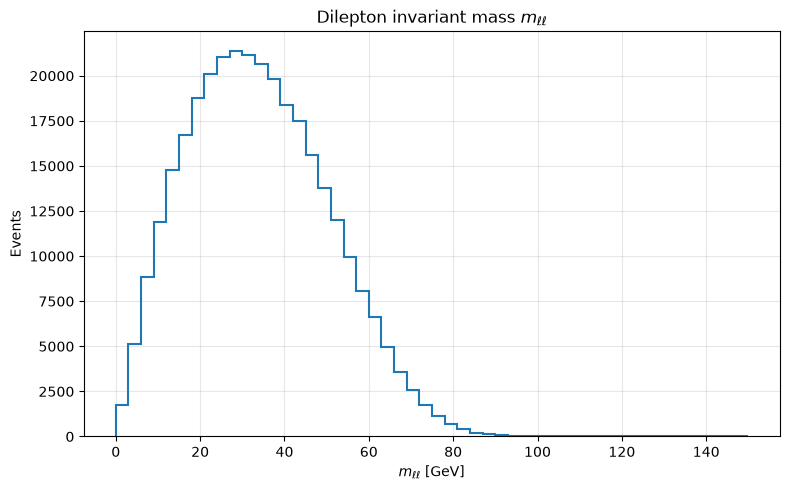

In [66]:
import uproot
import matplotlib.pyplot as plt
import numpy as np

with uproot.open("Higgs.root") as f:
    mll = f["Events"].arrays(["mll"], library="np")["mll"]

# Remove undefined values
mll = mll[mll > 0]

print("Number of entries:", len(mll))
print("Minimum:", np.min(mll))
print("Maximum:", np.max(mll))

plt.figure(figsize=(8, 5))

plt.hist(
    mll,
    bins=50,
    range=(0, 150),
    histtype="step",
    linewidth=1.5
)

plt.xlabel(r"$m_{\ell\ell}$ [GeV]")
plt.ylabel("Events")
plt.title(r"Dilepton invariant mass $m_{\ell\ell}$")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()